<a href="https://colab.research.google.com/github/sreeparvathitk/python-projects/blob/main/student_mark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from scipy.stats import norm

In [62]:
df = pd.read_csv('/content/Student_Marks.csv')
df

,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299
...,...,...,...
95,6,3.561,19.128
96,3,0.301,5.609
97,4,7.163,41.444
98,7,0.309,12.027


In [63]:
#display first 10 rows
df.head(10)

,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299
5,6,3.211,17.822
6,3,6.063,29.889
7,5,3.413,17.264
8,4,4.410,20.348
9,3,6.173,30.862


In [64]:
#display last 5 rows
df.tail()

,number_courses,time_study,Marks
95,6,3.561,19.128
96,3,0.301,5.609
97,4,7.163,41.444
98,7,0.309,12.027
99,3,6.335,32.357


In [65]:
# number of rows and columns
df.shape

(100, 3)

In [66]:
#display column names
df.columns

Index(['number_courses', 'time_study', 'Marks'], dtype='object')

In [67]:
#check datatypes
df.info


<bound method DataFrame.info of     number_courses  time_study   Marks
0                3       4.508  19.202
1                4       0.096   7.734
2                4       3.133  13.811
3                6       7.909  53.018
4                8       7.811  55.299
..             ...         ...     ...
95               6       3.561  19.128
96               3       0.301   5.609
97               4       7.163  41.444
98               7       0.309  12.027
99               3       6.335  32.357

[100 rows x 3 columns]>

In [68]:
#check missing values
df.isnull().sum()

,0
number_courses,0
time_study,0
Marks,0


In [69]:
# Check for duplicate records
df.duplicated().sum()

np.int64(0)

In [70]:
# to perform statistical analysis
df.describe()

,number_courses,time_study,Marks
count,100.000000,100.000000,100.000000
mean,5.290000,4.077140,24.417690
std,1.799523,2.372914,14.326199
min,3.000000,0.096000,5.609000
25%,4.000000,2.058500,12.633000
50%,5.000000,4.022000,20.059500
75%,7.000000,6.179250,36.676250
max,8.000000,7.957000,55.299000


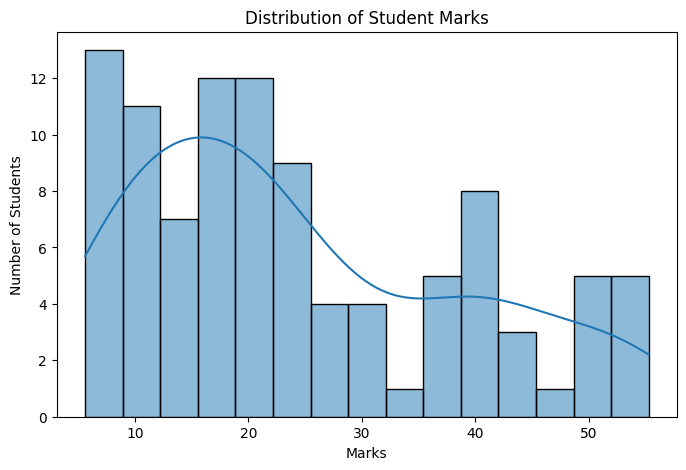

In [71]:
#analyse the distribution of marks
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Marks', bins=15, kde=True)

plt.title('Distribution of Student Marks')
plt.xlabel('Marks')
plt.ylabel('Number of Students')

plt.show()

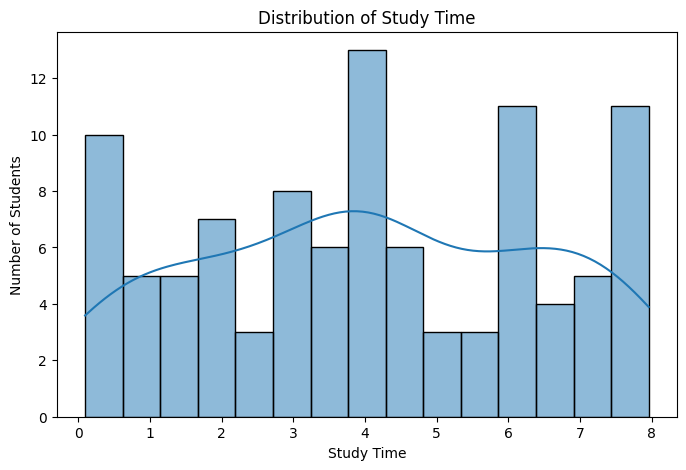

In [72]:
#analyse study time
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='time_study', bins=15, kde=True)

plt.title('Distribution of Study Time')
plt.xlabel('Study Time')
plt.ylabel('Number of Students')

plt.show()

In [73]:
df['time_study'].mean()

np.float64(4.07714)

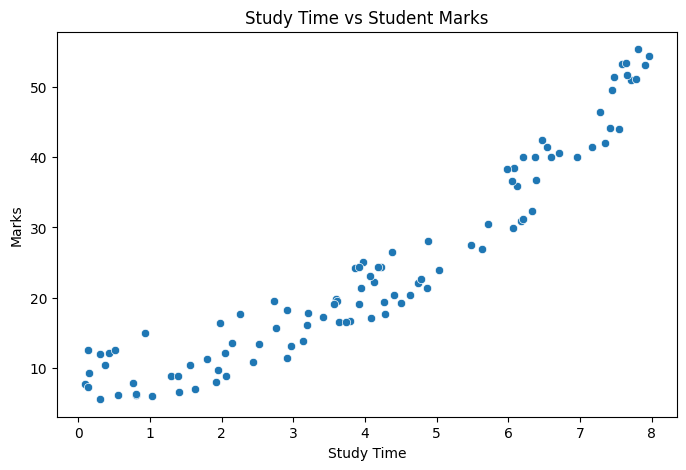

In [74]:
#relationship between studytime and marks
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='time_study',
    y='Marks'
)

plt.title('Study Time vs Student Marks')
plt.xlabel('Study Time')
plt.ylabel('Marks')

plt.show()

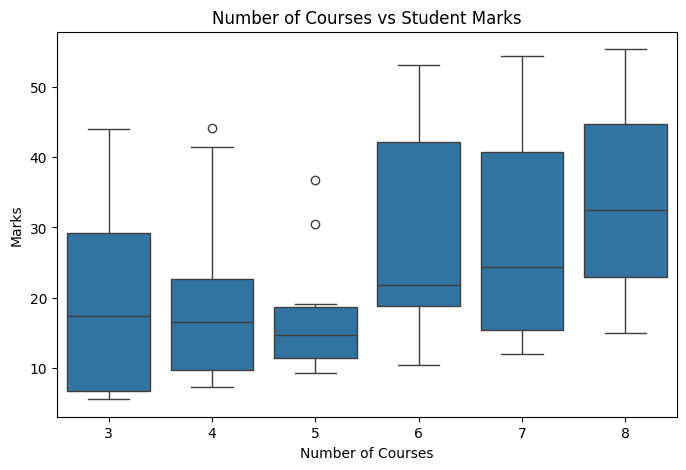

In [75]:
# number of courses and marks
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='number_courses',
    y='Marks'
)

plt.title('Number of Courses vs Student Marks')
plt.xlabel('Number of Courses')
plt.ylabel('Marks')

plt.show()

In [76]:
#correlation
df.corr(numeric_only=True)

,number_courses,time_study,Marks
number_courses,1.000000,0.204844,0.417335
time_study,0.204844,1.000000,0.942254
Marks,0.417335,0.942254,1.000000


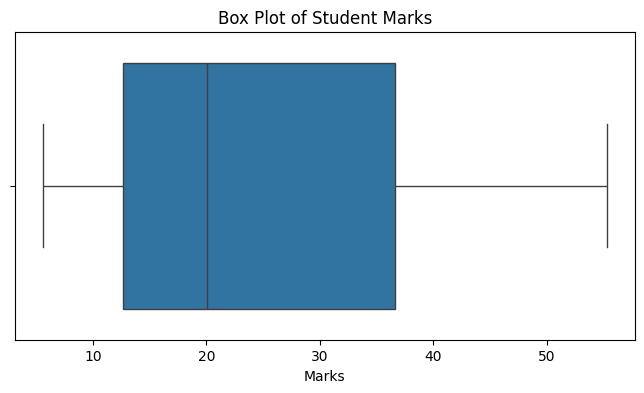

In [77]:
#outliers
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['Marks'])

plt.title('Box Plot of Student Marks')
plt.xlabel('Marks')

plt.show()

In [78]:
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outliers:")
print(outliers)

Lower limit: -23.431874999999994
Upper limit: 72.74112499999998
Potential outliers:
Empty DataFrame
Columns: [number_courses, time_study, Marks]
Index: []


In [79]:
#compare average marks
average_marks = df.groupby('number_courses')['Marks'].mean()
print(average_marks)

number_courses
3    18.433318
4    19.029952
5    17.641000
6    29.863062
7    29.401467
8    33.835375
Name: Marks, dtype: float64


APPLICATION OF Z-SCORE

In [80]:
# calculating z score of the marks column
df['Marks_Zscore'] = zscore(df['Marks'])
print(df[['Marks', 'Marks_Zscore']])

     Marks  Marks_Zscore
0   19.202     -0.365901
1    7.734     -1.170425
2   13.811     -0.744100
3   53.018      2.006422
4   55.299      2.166442
..     ...           ...
95  19.128     -0.371092
96   5.609     -1.319502
97  41.444      1.194461
98  12.027     -0.869254
99  32.357      0.556973

[100 rows x 2 columns]


detecting outliers using Z-score


In [81]:
# Z-scores of marks
df['Marks_Zscore'] = zscore(df['Marks'])

In [82]:
#Find the outliers.
outliers = df[abs(df['Marks_Zscore']) > 3]
print(outliers)

Empty DataFrame
Columns: [number_courses, time_study, Marks, Marks_Zscore]
Index: []


In [83]:
#Count the outliers.
print(len(outliers))

0


probablity using Z-score

In [84]:
#Calculate the probability
mean = df['Marks'].mean()
std = df['Marks'].std()

probability = norm.cdf(30, mean, std)

print(probability)
print("Percentage:", probability * 100)

0.6516050677754672
Percentage: 65.16050677754673


In [85]:
#Probability of scoring above 30
probability = 1 - norm.cdf(30, mean, std)

print("Probability:", probability)
print("Percentage:", probability * 100)

Probability: 0.34839493222453277
Percentage: 34.83949322245328


In [86]:
#Find the Z-score of 30 Marks
z = (30 - mean) / std
print("Z-score:", z)

Z-score: 0.3896574497713843


Scaling using Z-score Standardization

In [87]:
columns = ['number_courses', 'time_study', 'Marks']

In [88]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df[columns])

scaled_df = pd.DataFrame(scaled_data, columns=columns)

print(scaled_df.head())

   number_courses  time_study     Marks
0       -1.278970    0.182489 -0.365901
1       -0.720468   -1.686195 -1.170425
2       -0.720468   -0.399887 -0.744100
3        0.396537    1.622968  2.006422
4        1.513541    1.581461  2.166442


In [90]:
print(scaled_df.mean())

number_courses    8.881784e-18
time_study        1.332268e-17
Marks             2.220446e-16
dtype: float64


In [91]:
print(scaled_df.std(ddof=0))

number_courses    1.0
time_study        1.0
Marks             1.0
dtype: float64
